# Random-forest baseline: Madrid training and Amsterdam transfer

This notebook trains and evaluates a first baseline using the **54 unscaled spectral/temporal features** from `preprocessing_age_labels.ipynb`. Run that notebook first if its artifacts are missing. Run all cells here in a clean kernel.

**Experiments fixed before inspecting scores:**

1. Madrid: compare a most-frequent dummy classifier with a random forest on five saved spatial folds.
2. Amsterdam zero-shot: apply the final Madrid forest without local labels.
3. Amsterdam target-only: train a new forest with 5, 25, 50, 100 or 200 labeled locations per class.
4. Amsterdam transfer: average the source forest and target forest probabilities with **fixed 50/50 weights**. This is a simple transfer baseline, not fine-tuning a forest or training a transferable neural representation.

Each Amsterdam budget is evaluated in five spatial folds and three seeded sampling repetitions. Compare methods on identical evaluation locations and adaptation samples. Hyperparameters and blend weights are not tuned using outer validation scores. All metrics are **development cross-validation**, not organizer test-set performance.

**Skills applied:** locally downloaded [scikit-learn](docs/upstream-skills/scikit-learn/SKILL.md) (supervised learning, pipelines and evaluation references) and [verification-before-completion](docs/upstream-skills/verification-before-completion/SKILL.md). Those instructions are available as directly read copies; `.agents` remains read-only.


## 1. Configuration, input integrity and reproducibility

Read the preprocessing schema rather than guessing column order. Verify artifact hashes to reject mismatched features, folds and sample membership. A fixed seed controls tree construction; a separate seed sequence controls nested few-shot sampling. Limit forest threads to avoid saturating a shared workstation. No new dependencies or external training services are used.

Random forests require no standardization. Median imputation remains inside each estimator pipeline and is fitted only on that estimator's training rows. The globally standardized arrays from the older notebook and the fold-0 demonstration arrays are deliberately not used for cross-validation.


In [ ]:
from pathlib import Path
import hashlib
import json
import os
import platform
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, confusion_matrix)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'pyproject.toml').is_file() and (p/'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter inside this project.')
INPUT = ROOT/'data'/'preprocessed_age_labels'
OUTPUT = ROOT/'data'/'baseline'
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 42
N_REPETITIONS = 3
SOURCE_WEIGHT = .5
N_JOBS = min(4, os.cpu_count() or 1)
RF_PARAMS = dict(n_estimators=150, max_features='sqrt', min_samples_leaf=2,
                 class_weight='balanced_subsample', n_jobs=N_JOBS)
CLASSES = np.array([1, 2, 3, 4])
CONFIG = json.loads((INPUT/'configuration.json').read_text())
FEATURES = CONFIG['default_feature_names']
N_FOLDS = CONFIG['n_folds']
BUDGETS = CONFIG['budgets']
assert CONFIG['default_features_scaled'] is False
assert N_FOLDS == 5 and BUDGETS == [5, 25, 50, 100, 200]
assert set(FEATURES).isdisjoint(
    {'age_class', 'weighted_mean_year', 'location_id', 'city', 'px_key', 'py_key', 'fold'})


def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(
            lambda: stream.read(8*1024*1024), b''): h.update(block)
    return h.hexdigest()


INPUT_FILES = ['configuration.json', 'madrid_supervised_features.parquet',
               'amsterdam_supervised_features.parquet', 'amsterdam_few_shot_membership.csv']
input_manifest = json.loads((INPUT/'manifest.json').read_text())
for name in INPUT_FILES:
    assert sha256(
        INPUT/name) == input_manifest[name]['sha256'], f'Input changed: {name}; rerun preprocessing.'
VERSION_INFO = {'python': platform.python_version(), 'numpy': np.__version__,
                'pandas': pd.__version__, 'scikit_learn': sklearn.__version__, 'joblib': joblib.__version__}
print('Versions:', VERSION_INFO)
print('Forest parameters (chosen before evaluation):', RF_PARAMS)
print('Features:', len(FEATURES), 'sampling repetitions:', N_REPETITIONS)

Versions: {'python': '3.14.4', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit_learn': '1.9.1', 'joblib': '1.6.0'}
Forest parameters (chosen before evaluation): {'n_estimators': 150, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'class_weight': 'balanced_subsample', 'n_jobs': 4}
Features: 54 sampling repetitions: 3


## 2. Validate geographic separation and supervised inputs

Each feature row is a unique location, already aggregated over its observed years. Folds are geographic blocks of 20 coordinate-key units. No block may cross a training/validation boundary. Their physical size is unverified, and touching blocks can still share spatial context; stronger spatial buffers remain a future evaluation improvement.

Amsterdam is used as development data. Madrid source training can use all Madrid labels when evaluating Amsterdam because the cities are disjoint. No Amsterdam evaluation label is used to fit either forest or its imputer.


In [2]:
tables = {city: pd.read_parquet(INPUT/f'{city.lower()}_supervised_features.parquet')
          for city in ['Madrid', 'Amsterdam']}
for city, table in tables.items():
    assert table.location_id.is_unique and table.city.eq(city).all()
    assert set(table.age_class.unique()) == set(CLASSES)
    assert table.groupby('spatial_group').fold.nunique().max() == 1
    assert set(table.fold.unique()) == set(range(N_FOLDS))
    assert not np.isinf(table[FEATURES].to_numpy()).any()
    for fold in range(N_FOLDS):
        train = table.loc[table.fold.ne(fold)]
        valid = table.loc[table.fold.eq(fold)]
        assert set(train.location_id).isdisjoint(valid.location_id)
        assert set(train.spatial_group).isdisjoint(valid.spatial_group)
        assert set(train.age_class) == set(valid.age_class) == set(CLASSES)
    print(city, table.shape, 'supervised locations')
    display(pd.crosstab(table.fold, table.age_class))
assert set(tables['Madrid'].location_id).isdisjoint(
    tables['Amsterdam'].location_id)

Madrid (76263, 73) supervised locations


age_class,1,2,3,4
fold,,,,
0,2759,5430,3735,3329
1,2759,5430,3735,3329
2,2758,5431,3734,3329
3,2759,5431,3734,3329
4,2759,5430,3734,3329


Amsterdam (25992, 73) supervised locations


age_class,1,2,3,4
fold,,,,
0,1513,1760,1349,575
1,1515,1762,1350,576
2,1513,1760,1349,576
3,1513,1760,1349,575
4,1514,1760,1348,575


## 3. Pipelines and metric collection

The most-frequent dummy establishes what a classifier can achieve without learning spectral relationships. The forest combines 150 seeded trees, uses square-root feature subsampling, and requires two observations per leaf. Training-only bootstrap class weighting limits majority-class dominance; no resampling occurs before splitting.

Use macro F1 as the primary score, always including all four classes. Also save accuracy, balanced accuracy, class-level precision/recall/F1/support, row-normalized confusion proportions, and every validation prediction. These enable independent metric checks. Timings for each forest fit are recorded; transfer metrics reuse the same target fit.


In [3]:
def make_model(kind='rf', seed=SEED):
    classifier = (RandomForestClassifier(random_state=seed, **RF_PARAMS) if kind == 'rf'
                  else DummyClassifier(strategy='most_frequent', random_state=seed))
    return Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('classifier', classifier)])


metric_rows = []
class_rows = []
confusion_rows = []
prediction_parts = []


def record(city, strategy, fold, validation, prediction, n=0, repetition=0, fit_seconds=0.):
    y = validation.age_class.to_numpy(dtype=int)
    prediction = np.asarray(prediction, dtype=int)
    assert len(y) == len(prediction) and set(prediction).issubset(set(CLASSES))
    metadata = dict(city=city, strategy=strategy, fold=fold,
                    samples_per_class=n, repetition=repetition)
    metric_rows.append({**metadata, 'n_validation': len(y), 'macro_f1': f1_score(y, prediction, labels=CLASSES, average='macro', zero_division=0),
                        'accuracy': accuracy_score(y, prediction), 'balanced_accuracy': balanced_accuracy_score(y, prediction),
                        'fit_seconds': fit_seconds})
    precision, recall, f1, support = precision_recall_fscore_support(
        y, prediction, labels=CLASSES, zero_division=0)
    for k, cls in enumerate(CLASSES):
        class_rows.append({**metadata, 'age_class': int(cls), 'precision': precision[k], 'recall': recall[k],
                           'f1': f1[k], 'support': int(support[k])})
    counts = confusion_matrix(y, prediction, labels=CLASSES)
    proportions = counts/counts.sum(axis=1, keepdims=True)
    for i, a in enumerate(CLASSES):
        for j, b in enumerate(CLASSES):
            confusion_rows.append({**metadata, 'true_class': int(a), 'predicted_class': int(b),
                                   'count': int(counts[i, j]), 'row_proportion': proportions[i, j]})
    part = validation[['location_id', 'age_class']].rename(
        columns={'age_class': 'y_true'}).copy()
    part['y_pred'] = prediction
    for key, value in metadata.items():
        part[key] = value
    prediction_parts.append(part)


def aligned_probabilities(model, X):
    # Never assume probability-column order matches a hand-written class order.
    probabilities = model.predict_proba(X)
    order = [list(model.classes_).index(cls) for cls in CLASSES]
    result = probabilities[:, order]
    assert np.isfinite(result).all() and np.allclose(result.sum(axis=1), 1)
    return result

## 4. Madrid baseline: five spatial validation folds

Train a fresh pipeline for each saved fold. Only that fold's training locations determine imputation medians and trees. Save out-of-fold predictions instead of reporting in-sample scores. A full-data source model will be trained only after this evaluation, for cross-city transfer and persistence.

Every location appears once in Madrid validation for each strategy. The score printed after each fit is held-out spatial-fold macro F1, not a training score.


In [4]:
madrid = tables['Madrid']
for fold in range(N_FOLDS):
    training = madrid.loc[madrid.fold.ne(fold)]
    validation = madrid.loc[madrid.fold.eq(fold)]
    for kind, strategy in [('dummy', 'dummy_most_frequent'), ('rf', 'random_forest')]:
        start = time.perf_counter()
        model = make_model(kind, SEED+fold)
        model.fit(training[FEATURES], training.age_class)
        fit_seconds = time.perf_counter()-start
        prediction = model.predict(validation[FEATURES])
        record('Madrid', strategy, fold, validation,
               prediction, fit_seconds=fit_seconds)
        print(
            f'Madrid fold {fold}, {strategy}: macro F1={metric_rows[-1]["macro_f1"]:.4f}; fit={fit_seconds:.1f}s', flush=True)
        del model
    gc.collect()

Madrid fold 0, dummy_most_frequent: macro F1=0.1313; fit=0.4s
Madrid fold 0, random_forest: macro F1=0.5747; fit=19.4s
Madrid fold 1, dummy_most_frequent: macro F1=0.1313; fit=0.3s
Madrid fold 1, random_forest: macro F1=0.5834; fit=19.4s
Madrid fold 2, dummy_most_frequent: macro F1=0.1313; fit=0.3s
Madrid fold 2, random_forest: macro F1=0.5967; fit=19.7s
Madrid fold 3, dummy_most_frequent: macro F1=0.1313; fit=0.3s
Madrid fold 3, random_forest: macro F1=0.5583; fit=19.8s
Madrid fold 4, dummy_most_frequent: macro F1=0.1313; fit=0.3s
Madrid fold 4, random_forest: macro F1=0.5643; fit=20.3s


## 5. Fit and save the final Madrid source model

Fit the same predefined random-forest pipeline on all available Madrid locations after cross-validation. This final model has **no new Madrid holdout score**: the previous section estimates the source training procedure's generalization. It can be evaluated directly on Amsterdam because no Amsterdam rows are involved in its fit.

Persist the complete imputer-plus-forest pipeline. This is the Stage 1 baseline artifact. Package versions and ordered features are exported later. Loading joblib is appropriate only for trusted artifacts with compatible versions.


In [5]:
start = time.perf_counter()
SOURCE_MODEL = make_model('rf', SEED)
SOURCE_MODEL.fit(madrid[FEATURES], madrid.age_class)
SOURCE_FIT_SECONDS = time.perf_counter()-start
joblib.dump(SOURCE_MODEL, OUTPUT/'madrid_source_model.joblib', compress=3)
print(
    f'Final Madrid source model fitted on {len(madrid):,} locations in {SOURCE_FIT_SECONDS:.1f}s.', flush=True)
amsterdam = tables['Amsterdam']
SOURCE_AMSTERDAM_PROBABILITIES = aligned_probabilities(
    SOURCE_MODEL, amsterdam[FEATURES])
SOURCE_AMSTERDAM_PREDICTIONS = CLASSES[SOURCE_AMSTERDAM_PROBABILITIES.argmax(
    axis=1)]
for fold in range(N_FOLDS):
    positions = np.flatnonzero(amsterdam.fold.eq(fold).to_numpy())
    record('Amsterdam', 'source_only', fold,
           amsterdam.iloc[positions], SOURCE_AMSTERDAM_PREDICTIONS[positions])
print('Source-only Amsterdam evaluation recorded on five spatial folds.')

Final Madrid source model fitted on 76,263 locations in 26.9s.
Source-only Amsterdam evaluation recorded on five spatial folds.


## 6. Few-shot adaptation and target-only comparison

The transfer baseline uses `p_transfer = 0.5*p_source + 0.5*p_target`. The target forest is trained on exactly `n` labels per class outside the evaluated Amsterdam fold. Probability columns are aligned explicitly. Keeping a fixed source forest makes this cheap and reproducible; the blend's probabilities are not claimed to be calibrated.

Target-only and transfer share the identical fitted target forest and labels. Budgets are nested within each repetition/fold. Repetition 0 must reproduce the membership exported by preprocessing. Two additional seeded repetitions expose sensitivity to scarce-label selection without treating repeated evaluation locations as independent test cases.

Save target/transfer bundles for fold 0, repetition 0, for each budget. Each bundle references the common source artifact instead of duplicating a large forest. These examples exclude fold 0 and are **not** final models trained on all Amsterdam labels.


In [6]:
def adaptation_sample(table, fold, n, repetition=0):
    if n not in BUDGETS or fold not in range(N_FOLDS):
        raise ValueError('Unknown budget or fold')
    pool = table.loc[table.fold.ne(fold)].set_index('location_id', drop=False)
    rng = np.random.default_rng(np.random.SeedSequence(
        [CONFIG['seed'], repetition, fold]))
    selected = []
    for cls in CLASSES:
        candidates = pool.loc[pool.age_class.eq(
            cls), 'location_id'].sort_values().to_numpy()
        if len(candidates) < max(BUDGETS):
            raise ValueError(f'Insufficient class {cls} adaptation locations')
        selected.extend(rng.permutation(candidates)[:n])
    sample = pool.loc[selected].reset_index(drop=True)
    evaluation = table.loc[table.fold.eq(fold)]
    assert len(sample) == 4*n and sample.location_id.is_unique
    assert sample.age_class.value_counts().reindex(CLASSES).eq(n).all()
    assert set(sample.location_id).isdisjoint(evaluation.location_id)
    assert set(sample.spatial_group).isdisjoint(evaluation.spatial_group)
    return sample


saved_membership = pd.read_csv(INPUT/'amsterdam_few_shot_membership.csv')
for fold in range(N_FOLDS):
    for n in BUDGETS:
        saved = set(saved_membership.loc[saved_membership.validation_fold.eq(
            fold) & saved_membership.samples_per_class.eq(n), 'location_id'])
        assert saved == set(adaptation_sample(
            amsterdam, fold, n, 0).location_id)


def fit_adaptation(source_model, table, fold, n, repetition=0):
    # This callable is the parameterized training procedure; evaluation rows never enter fit().
    sample = adaptation_sample(table, fold, n, repetition)
    seed = SEED+10_000+100*fold+repetition
    target = make_model('rf', seed)
    target.fit(sample[FEATURES], sample.age_class)
    return target, sample


adaptation_memberships = []
for fold in range(N_FOLDS):
    positions = np.flatnonzero(amsterdam.fold.eq(fold).to_numpy())
    validation = amsterdam.iloc[positions]
    source_prob = SOURCE_AMSTERDAM_PROBABILITIES[positions]
    for repetition in range(N_REPETITIONS):
        for n in BUDGETS:
            start = time.perf_counter()
            target, sample = fit_adaptation(
                SOURCE_MODEL, amsterdam, fold, n, repetition)
            elapsed = time.perf_counter()-start
            target_prob = aligned_probabilities(target, validation[FEATURES])
            transfer_prob = SOURCE_WEIGHT*source_prob + \
                (1-SOURCE_WEIGHT)*target_prob
            record('Amsterdam', 'target_only', fold, validation,
                   CLASSES[target_prob.argmax(axis=1)], n, repetition, elapsed)
            record('Amsterdam', 'source_target_blend', fold, validation,
                   CLASSES[transfer_prob.argmax(axis=1)], n, repetition, elapsed)
            membership = sample[['location_id', 'age_class']].copy()
            membership['fold'] = fold
            membership['samples_per_class'] = n
            membership['repetition'] = repetition
            adaptation_memberships.append(membership)
            if fold == 0 and repetition == 0:
                bundle = {'target_pipeline': target, 'source_model_file': 'madrid_source_model.joblib',
                          'source_weight': SOURCE_WEIGHT, 'feature_names': FEATURES, 'class_order': CLASSES,
                          'excluded_Amsterdam_fold': fold, 'samples_per_class': n, 'repetition': repetition,
                          'adaptation_location_ids': sample.location_id.to_list()}
                joblib.dump(bundle, OUTPUT /
                            f'amsterdam_fold0_n{n}_rep0.joblib', compress=3)
            print(
                f'Amsterdam fold {fold}, repetition {repetition}, {n}/class: target F1={metric_rows[-2]["macro_f1"]:.4f}, transfer F1={metric_rows[-1]["macro_f1"]:.4f}', flush=True)
            del target
    gc.collect()

Amsterdam fold 0, repetition 0, 5/class: target F1=0.4048, transfer F1=0.4146
Amsterdam fold 0, repetition 0, 25/class: target F1=0.5493, transfer F1=0.5220
Amsterdam fold 0, repetition 0, 50/class: target F1=0.5809, transfer F1=0.5814
Amsterdam fold 0, repetition 0, 100/class: target F1=0.5980, transfer F1=0.5977
Amsterdam fold 0, repetition 0, 200/class: target F1=0.6001, transfer F1=0.5992
Amsterdam fold 0, repetition 1, 5/class: target F1=0.4281, transfer F1=0.4696
Amsterdam fold 0, repetition 1, 25/class: target F1=0.5246, transfer F1=0.5439
Amsterdam fold 0, repetition 1, 50/class: target F1=0.5646, transfer F1=0.5649
Amsterdam fold 0, repetition 1, 100/class: target F1=0.5856, transfer F1=0.5854
Amsterdam fold 0, repetition 1, 200/class: target F1=0.5912, transfer F1=0.5937
Amsterdam fold 0, repetition 2, 5/class: target F1=0.4232, transfer F1=0.4672
Amsterdam fold 0, repetition 2, 25/class: target F1=0.5175, transfer F1=0.5324
Amsterdam fold 0, repetition 2, 50/class: target F1

## 7. Summarize cross-validation correctly

First average the three repetitions **within each fold**, then report the mean and sample standard deviation across the five spatial folds. Repetitions reuse validation locations and are not 15 independent test folds. The standard deviation describes fold heterogeneity, not a confidence interval. Also report mean within-fold sampling SD as a separate diagnostic.

Pooled out-of-fold class metrics can differ from averages of fold metrics. We export fold-level precision, recall, F1, support and confusion proportions, and explicitly label the pooled Madrid classification report.


In [7]:
METRICS = pd.DataFrame(metric_rows)
CLASS_METRICS = pd.DataFrame(class_rows)
CONFUSIONS = pd.DataFrame(confusion_rows)
PREDICTIONS = pd.concat(prediction_parts, ignore_index=True)
MEMBERSHIPS = pd.concat(adaptation_memberships, ignore_index=True)
GROUP = ['city', 'strategy', 'samples_per_class']
FOLD_MEANS = METRICS.groupby(
    GROUP+['fold'], as_index=False)[['macro_f1', 'accuracy', 'balanced_accuracy']].mean()
SUMMARY = FOLD_MEANS.groupby(GROUP, as_index=False).agg(
    macro_f1_mean=('macro_f1', 'mean'), macro_f1_fold_sd=('macro_f1', 'std'),
    accuracy_mean=('accuracy', 'mean'), balanced_accuracy_mean=('balanced_accuracy', 'mean'), n_folds=('fold', 'nunique'))
sampling = METRICS.groupby(GROUP+['fold']).macro_f1.std().groupby(
    GROUP).mean().fillna(0).rename('mean_within_fold_sampling_sd').reset_index()
SUMMARY = SUMMARY.merge(sampling, on=GROUP, validate='one_to_one')
display(SUMMARY.round(4))
print('Madrid pooled out-of-fold class metrics (RF):')
pooled = PREDICTIONS.loc[PREDICTIONS.city.eq(
    'Madrid') & PREDICTIONS.strategy.eq('random_forest')]
p, r, f, s = precision_recall_fscore_support(
    pooled.y_true, pooled.y_pred, labels=CLASSES, zero_division=0)
POOLED_MADRID_CLASSES = pd.DataFrame(
    {'age_class': CLASSES, 'precision': p, 'recall': r, 'f1': f, 'support': s})
display(POOLED_MADRID_CLASSES.round(4))
print('Amsterdam mean class metrics across repetitions/folds:')
CLASS_SUMMARY = CLASS_METRICS.groupby(
    GROUP+['age_class'], as_index=False)[['precision', 'recall', 'f1']].mean()
display(CLASS_SUMMARY.loc[CLASS_SUMMARY.samples_per_class.eq(25)].round(4))

,city,strategy,samples_per_class,macro_f1_mean,macro_f1_fold_sd,accuracy_mean,balanced_accuracy_mean,n_folds,mean_within_fold_sampling_sd
0,Amsterdam,source_only,0,0.3462,0.0152,0.4124,0.3720,5,0.0000
1,Amsterdam,source_target_blend,5,0.4737,0.0279,0.4970,0.4841,5,0.0379
2,Amsterdam,source_target_blend,25,0.5494,0.0258,0.5652,0.5559,5,0.0181
3,Amsterdam,source_target_blend,50,0.5887,0.0254,0.6002,0.5928,5,0.0139
4,Amsterdam,source_target_blend,100,0.6168,0.0232,0.6256,0.6228,5,0.0085
5,Amsterdam,source_target_blend,200,0.6321,0.0233,0.6402,0.6374,5,0.0053
6,Amsterdam,target_only,5,0.4322,0.0288,0.4560,0.4669,5,0.0457
7,Amsterdam,target_only,25,0.5393,0.0232,0.5512,0.5630,5,0.0199
8,Amsterdam,target_only,50,0.5822,0.0240,0.5925,0.6047,5,0.0178
9,Amsterdam,target_only,100,0.6127,0.0224,0.6214,0.6359,5,0.0124


Madrid pooled out-of-fold class metrics (RF):


,age_class,precision,recall,f1,support
0,1,0.6173,0.3970,0.4832,13794
1,2,0.5597,0.7484,0.6405,27152
2,3,0.5802,0.4878,0.5300,18672
3,4,0.6764,0.6252,0.6498,16645


Amsterdam mean class metrics across repetitions/folds:


,city,strategy,samples_per_class,age_class,precision,recall,f1
8,Amsterdam,source_target_blend,25,1,0.7228,0.5687,0.6337
9,Amsterdam,source_target_blend,25,2,0.5169,0.6836,0.5872
10,Amsterdam,source_target_blend,25,3,0.6134,0.4075,0.4847
11,Amsterdam,source_target_blend,25,4,0.4487,0.5639,0.4919
28,Amsterdam,target_only,25,1,0.6610,0.6357,0.6462
29,Amsterdam,target_only,25,2,0.5860,0.4881,0.5299
30,Amsterdam,target_only,25,3,0.5508,0.5104,0.5268
31,Amsterdam,target_only,25,4,0.3640,0.6178,0.4544


## 8. Learning curves and confusion matrices

Plot mean F1 against log2(samples per class), with error bars showing the SD across five fold means. The source-only horizontal line uses zero Amsterdam labels. Shared folds and samples make target-only versus transfer comparisons paired.

For confusion plots, normalize rows inside each evaluation run, average repetitions within each fold and then average folds. Rows represent true classes; columns predicted classes. No claim of statistical significance follows from visual error-bar overlap.


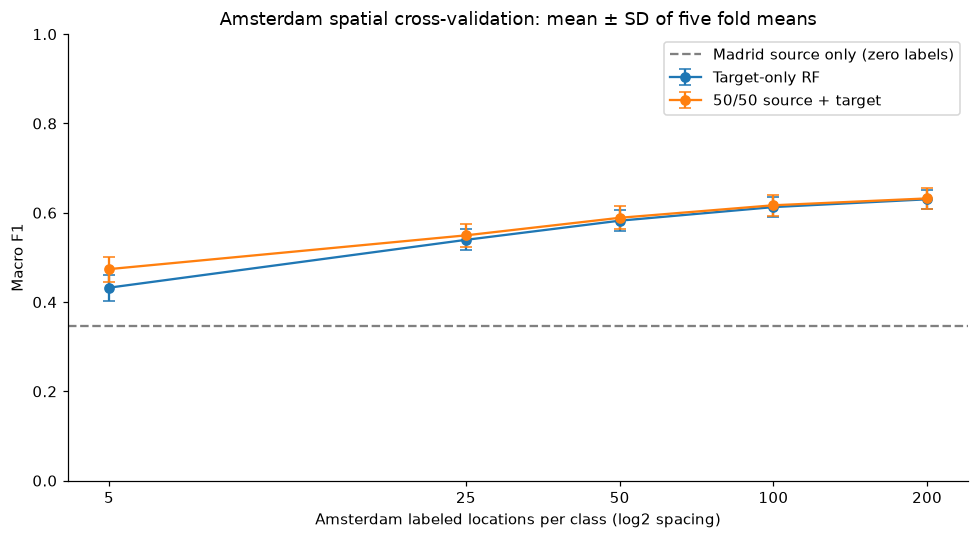

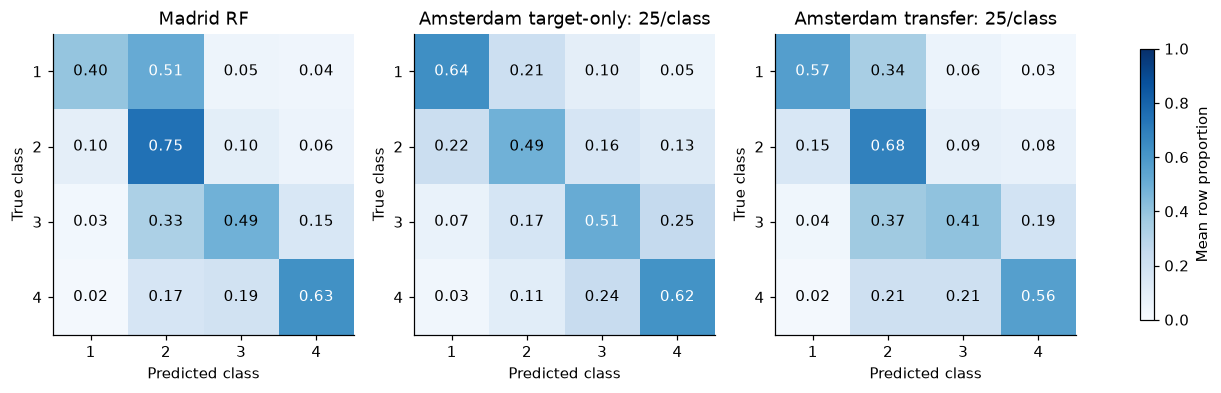

In [8]:
plt.rcParams.update(
    {'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(9, 5))
for strategy, label in [('target_only', 'Target-only RF'), ('source_target_blend', '50/50 source + target')]:
    sub = SUMMARY.loc[SUMMARY.strategy.eq(
        strategy)].sort_values('samples_per_class')
    ax.errorbar(np.log2(sub.samples_per_class), sub.macro_f1_mean, yerr=sub.macro_f1_fold_sd,
                marker='o', capsize=4, label=label)
source_result = SUMMARY.loc[SUMMARY.strategy.eq('source_only')].iloc[0]
ax.axhline(source_result.macro_f1_mean, color='gray',
           ls='--', label='Madrid source only (zero labels)')
ax.set_xticks(np.log2(BUDGETS), [str(n) for n in BUDGETS])
ax.set(xlabel='Amsterdam labeled locations per class (log2 spacing)', ylabel='Macro F1', ylim=(0, 1),
       title='Amsterdam spatial cross-validation: mean ± SD of five fold means')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT/'amsterdam_learning_curve.png', bbox_inches='tight')
plt.show()


def mean_confusion(city, strategy, n):
    subset = CONFUSIONS.loc[CONFUSIONS.city.eq(city) & CONFUSIONS.strategy.eq(
        strategy) & CONFUSIONS.samples_per_class.eq(n)]
    per_fold = subset.groupby(
        ['fold', 'true_class', 'predicted_class']).row_proportion.mean()
    return per_fold.groupby(['true_class', 'predicted_class']).mean().unstack().reindex(index=CLASSES, columns=CLASSES)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (city, strategy, n, title) in zip(axes, [('Madrid', 'random_forest', 0, 'Madrid RF'),
                                                 ('Amsterdam', 'target_only', 25,
                                                  'Amsterdam target-only: 25/class'),
                                                 ('Amsterdam', 'source_target_blend', 25, 'Amsterdam transfer: 25/class')]):
    matrix = mean_confusion(city, strategy, n)
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{matrix.iloc[i, j]:.2f}', ha='center', va='center',
                    color='white' if matrix.iloc[i, j] > .5 else 'black')
    ax.set_xticks(range(4), CLASSES)
    ax.set_yticks(range(4), CLASSES)
    ax.set(title=title, xlabel='Predicted class', ylabel='True class')
fig.colorbar(im, ax=axes.ravel().tolist(),
             shrink=.8, label='Mean row proportion')
fig.savefig(OUTPUT/'baseline_confusion_matrices.png', bbox_inches='tight')
plt.show()

## 9. Verify predictions, leakage controls and model reloads

Recompute every recorded F1 score from saved predictions rather than trusting summary tables. Check expected run counts, unique validation predictions, exact label budgets, nested samples and absence of evaluation-location/block overlap. Compare reloaded model predictions and probabilities with the original artifacts to verify persistence.

Final fitted source-model predictions on Madrid training data are not reported as evaluation. No feature importances are used to alter this first experiment. Any model choice prompted by these scores needs further inner-validation work and an untouched external test set.


In [9]:
RUN_KEYS = GROUP+['fold', 'repetition']
assert len(METRICS) == 2*N_FOLDS+N_FOLDS+2*N_FOLDS*N_REPETITIONS*len(BUDGETS)
assert not PREDICTIONS.duplicated(RUN_KEYS+['location_id']).any()
assert SUMMARY.n_folds.eq(N_FOLDS).all()
checks = []
for key, group in PREDICTIONS.groupby(RUN_KEYS, sort=False):
    checks.append(dict(zip(RUN_KEYS, key)) | {'recomputed_f1': f1_score(
        group.y_true, group.y_pred, labels=CLASSES, average='macro', zero_division=0)})
checked = METRICS.merge(pd.DataFrame(
    checks), on=RUN_KEYS, validate='one_to_one')
np.testing.assert_allclose(checked.macro_f1, checked.recomputed_f1)
for (fold, rep, n), sample in MEMBERSHIPS.groupby(['fold', 'repetition', 'samples_per_class']):
    assert sample.location_id.is_unique
    assert sample.age_class.value_counts().reindex(CLASSES).eq(n).all()
    selected = amsterdam.set_index('location_id').loc[sample.location_id]
    assert selected.fold.ne(fold).all()
    assert set(selected.spatial_group).isdisjoint(
        amsterdam.loc[amsterdam.fold.eq(fold), 'spatial_group'])
for (fold, rep), group in MEMBERSHIPS.groupby(['fold', 'repetition']):
    previous = set()
    for n in BUDGETS:
        current = set(group.loc[group.samples_per_class.eq(n), 'location_id'])
        assert previous.issubset(current)
        previous = current
restored_source = joblib.load(OUTPUT/'madrid_source_model.joblib')
probe = amsterdam[FEATURES].iloc[:64]
np.testing.assert_allclose(aligned_probabilities(
    restored_source, probe), aligned_probabilities(SOURCE_MODEL, probe))
for n in BUDGETS:
    bundle = joblib.load(OUTPUT/f'amsterdam_fold0_n{n}_rep0.joblib')
    sample = adaptation_sample(amsterdam, 0, n, 0)
    assert set(bundle['adaptation_location_ids']) == set(sample.location_id)
    validation = amsterdam.loc[amsterdam.fold.eq(0)]
    target_prob = aligned_probabilities(
        bundle['target_pipeline'], validation[FEATURES])
    source_prob = aligned_probabilities(restored_source, validation[FEATURES])
    prediction = CLASSES[(bundle['source_weight']*source_prob +
                          (1-bundle['source_weight'])*target_prob).argmax(axis=1)]
    saved = PREDICTIONS.loc[PREDICTIONS.city.eq('Amsterdam') & PREDICTIONS.strategy.eq('source_target_blend') &
                            PREDICTIONS.fold.eq(0) & PREDICTIONS.repetition.eq(0) & PREDICTIONS.samples_per_class.eq(n)].set_index('location_id')
    np.testing.assert_array_equal(
        prediction, saved.loc[validation.location_id, 'y_pred'].to_numpy())
print('All recorded scores, 75 exact-budget adaptation sets, nested samples, spatial separation and six saved model artifacts verified.')

All recorded scores, 75 exact-budget adaptation sets, nested samples, spatial separation and six saved model artifacts verified.


## 10. Export results, provenance and a concise experiment report

Outputs include raw fold metrics, class metrics, confusion counts/proportions, validation predictions, adaptation memberships, charts and model artifacts. Save package versions, feature order, input hashes, fixed hyperparameters and the 50/50 transfer rule. This makes results reviewable without rerunning training.

`docs/BASELINE_RESULTS.md` summarizes this run. Its scores describe the fixed baseline procedures; the best observed budget is descriptive and is not selected as an unbiased deployment estimate. Three sampling repetitions are a modest baseline, not an exhaustive uncertainty study. Class 1/2 have city-specific historical boundaries, so transfer class semantics differ somewhat between cities.


In [10]:
METRICS.to_csv(OUTPUT/'fold_metrics.csv', index=False)
SUMMARY.to_csv(OUTPUT/'summary.csv', index=False)
FOLD_MEANS.to_csv(OUTPUT/'fold_mean_metrics.csv', index=False)
CLASS_METRICS.to_csv(OUTPUT/'class_metrics.csv', index=False)
CLASS_SUMMARY.to_csv(OUTPUT/'class_summary.csv', index=False)
POOLED_MADRID_CLASSES.to_csv(
    OUTPUT/'madrid_pooled_class_metrics.csv', index=False)
CONFUSIONS.to_csv(OUTPUT/'confusion_matrices.csv', index=False)
PREDICTIONS.to_parquet(OUTPUT/'validation_predictions.parquet', index=False)
MEMBERSHIPS.to_csv(OUTPUT/'adaptation_membership.csv', index=False)
provenance = {'seed': SEED, 'repetitions': N_REPETITIONS, 'feature_names': FEATURES, 'class_order': CLASSES.tolist(),
              'rf_parameters': RF_PARAMS, 'source_weight': SOURCE_WEIGHT, 'versions': VERSION_INFO,
              'input_hashes': {name: sha256(INPUT/name) for name in INPUT_FILES},
              'preprocessing_configuration': CONFIG, 'source_fit_seconds': SOURCE_FIT_SECONDS,
              'score_definition': 'mean across five spatial folds after averaging repetitions within each fold; SD across fold means',
              'hyperparameter_search_performed': False, 'organizer_test_sets_used': False}
(OUTPUT/'experiment.json').write_text(json.dumps(provenance, indent=2)+'\n')


def fmt(row): return f'{row.macro_f1_mean:.4f} ± {row.macro_f1_fold_sd:.4f}'


source_row = SUMMARY.loc[SUMMARY.strategy.eq('source_only')].iloc[0]
rf_row = SUMMARY.loc[SUMMARY.city.eq(
    'Madrid') & SUMMARY.strategy.eq('random_forest')].iloc[0]
dummy_row = SUMMARY.loc[SUMMARY.city.eq(
    'Madrid') & SUMMARY.strategy.eq('dummy_most_frequent')].iloc[0]
report = ['# First random-forest baseline', '',
          f'Madrid spatial CV macro F1: **{fmt(rf_row)}**. Most-frequent dummy: **{fmt(dummy_row)}**.',
          f'Amsterdam without adaptation: **{fmt(source_row)}** (zero local labels).', '',
          'Scores are means ± sample SD across five spatial folds. Amsterdam target/transfer scores average three sampling repetitions within each fold first. Fold SD is not a confidence interval.', '',
          '| Amsterdam labels per class | Target-only RF | 50/50 source + target |',
          '| ---: | ---: | ---: |']
for n in BUDGETS:
    target = SUMMARY.loc[SUMMARY.strategy.eq(
        'target_only') & SUMMARY.samples_per_class.eq(n)].iloc[0]
    transfer = SUMMARY.loc[SUMMARY.strategy.eq(
        'source_target_blend') & SUMMARY.samples_per_class.eq(n)].iloc[0]
    report.append(f'| {n} | {fmt(target)} | {fmt(transfer)} |')
report += ['', '## Method and validation', '',
           '- 54 unscaled spectral/temporal predictors, 76,263 Madrid and 25,992 Amsterdam locations; observations restricted to 1984–2024.',
           '- Median imputation is fitted inside each training pipeline. IDs, coordinates, construction years and availability indicators are excluded from predictors.',
           '- Random forest: 150 trees, minimum leaf size 2, square-root feature sampling, bootstrap class weighting. No hyperparameter search.',
           '- Five fixed spatial folds group 20 coordinate-key blocks. Each Amsterdam adaptation sample excludes the evaluated fold and its blocks.',
           '- Target-only and transfer use identical nested label samples. Transfer averages the fixed Madrid model and target model probabilities with predefined equal weights.',
           '- All scores are development cross-validation. Organizer test sets were not accessed. Spatial block boundaries can touch; no buffer was applied.',
           '- Class boundaries reproduce existing right-closed bins (Madrid event 1960; Amsterdam event 1945). Organizer confirmation remains needed.', '',
           '## Artifacts and reproduction', '',
           'Run `preprocessing_age_labels.ipynb`, then `baseline.ipynb`. Trained pipelines, model bundles, fold/class metrics, predictions, memberships, plots and exact configuration are in `data/baseline/` (generated, gitignored). The Stage 1 pipeline is `madrid_source_model.joblib`; five saved Amsterdam bundles use fold 0 / repetition 0 and reference that source artifact. They are demonstration adaptations, not models trained using the evaluation fold.', '',
           'The notebook verifies every F1 score against predictions, all label budgets and spatial exclusions, model reload predictions, and exported files. No scores are inferred from training accuracy.', '',
           '## Skills', '',
           'Applied the downloaded K-Dense-AI scikit-learn skill and obra verification-before-completion skill. Provenance is in `docs/upstream-skills/`. These directly read copies are not registered `.agents` installations.', '',
           'Kassis, T., Agarwal, V., He, Y., Patel, D., & Brueckner, A. M. (2026). *Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents*. https://doi.org/10.48550/arXiv.2609.00065.']
(ROOT/'docs'/'BASELINE_RESULTS.md').write_text('\n'.join(report)+'\n')
# Re-read exported metrics and predictions to check persisted results, not just in-memory objects.
pd.testing.assert_frame_equal(SUMMARY, pd.read_csv(
    OUTPUT/'summary.csv'), check_exact=False, rtol=1e-12, atol=1e-12)
pd.testing.assert_frame_equal(PREDICTIONS, pd.read_parquet(
    OUTPUT/'validation_predictions.parquet'))
manifest = {p.name: {'sha256': sha256(p), 'bytes': p.stat().st_size} for p in sorted(
    OUTPUT.iterdir()) if p.is_file() and p.name != 'manifest.json'}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
print('Export round-trip checks passed. Artifacts:', OUTPUT)
print('Experiment report:', ROOT/'docs'/'BASELINE_RESULTS.md')
display(SUMMARY[['city', 'strategy', 'samples_per_class',
        'macro_f1_mean', 'macro_f1_fold_sd']].round(4))

Export round-trip checks passed. Artifacts: /home/mirado/hack4dev/Building_Age_Classification/data/baseline
Experiment report: /home/mirado/hack4dev/Building_Age_Classification/docs/BASELINE_RESULTS.md


,city,strategy,samples_per_class,macro_f1_mean,macro_f1_fold_sd
0,Amsterdam,source_only,0,0.3462,0.0152
1,Amsterdam,source_target_blend,5,0.4737,0.0279
2,Amsterdam,source_target_blend,25,0.5494,0.0258
3,Amsterdam,source_target_blend,50,0.5887,0.0254
4,Amsterdam,source_target_blend,100,0.6168,0.0232
5,Amsterdam,source_target_blend,200,0.6321,0.0233
6,Amsterdam,target_only,5,0.4322,0.0288
7,Amsterdam,target_only,25,0.5393,0.0232
8,Amsterdam,target_only,50,0.5822,0.0240
9,Amsterdam,target_only,100,0.6127,0.0224


## 11. Inference example and next experiments

Load the source pipeline and a saved Amsterdam bundle from trusted local artifacts. Use the exact ordered feature schema and the same deterministic upstream feature construction. The helper below predicts target-only or transfer probabilities without accessing labels. It does not create features from raw imagery.

Potential next experiments are source-weight selection on **inner** development folds, stronger spatial buffers, availability-feature ablations, and more sampling repetitions. Do not retune a blend on these same outer folds and then present its score as an unbiased improvement. A metric-learning approach should be compared on the identical folds, label budgets and metrics.

Skill citation: Kassis et al. (2026), [Scientific Agent Skills](https://doi.org/10.48550/arXiv.2609.00065), as referenced in preprocessing and the experiment report. Official references: [random forests](https://scikit-learn.org/stable/modules/ensemble.html#forest), [pipelines](https://scikit-learn.org/stable/modules/compose.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).


In [11]:
def predict_with_saved_adaptation(feature_table, bundle_path):
    bundle = joblib.load(bundle_path)
    source = joblib.load(Path(bundle_path).parent/bundle['source_model_file'])
    ordered = feature_table[bundle['feature_names']]
    class_order = np.asarray(bundle['class_order'])

    def proba(model):
        values = model.predict_proba(ordered)
        return values[:, [list(model.classes_).index(c) for c in class_order]]
    probabilities = bundle['source_weight']*proba(source)+(
        1-bundle['source_weight'])*proba(bundle['target_pipeline'])
    return class_order[probabilities.argmax(axis=1)], probabilities


example = amsterdam.loc[amsterdam.fold.eq(0)].head(8)
example_prediction, example_probabilities = predict_with_saved_adaptation(
    example, OUTPUT/'amsterdam_fold0_n25_rep0.joblib')
assert example_probabilities.shape == (8, 4) and np.allclose(
    example_probabilities.sum(axis=1), 1)
display(pd.DataFrame({'location_id': example.location_id.to_numpy(
), 'predicted_age_class': example_prediction}))
print('Inference example verified. All reported evaluation metrics are saved separately from this illustration.')

,location_id,predicted_age_class
0,Amsterdam:20641:193600,3
1,Amsterdam:20641:193601,3
2,Amsterdam:20641:193603,3
3,Amsterdam:20642:193600,3
4,Amsterdam:20642:193602,3
5,Amsterdam:20642:193605,3
6,Amsterdam:20642:193606,3
7,Amsterdam:20642:193610,4


Inference example verified. All reported evaluation metrics are saved separately from this illustration.
